In [388]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [389]:
orders = pd.read_csv('Downloads/datasets/data_orders.csv')
offers = pd.read_csv('Downloads/datasets/data_offers.csv')

In [390]:
print(orders.shape)
orders.head(10)

(10716, 8)


,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0
1,20:57:32,-0.950385,51.456843,NaN,3000583116437,4,0,128.0
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0
4,21:24:45,-0.967605,51.458236,NaN,3000583140877,9,0,NaN
5,21:21:23,-0.947011,51.456380,NaN,3000583117054,9,0,NaN
6,07:58:15,-0.955637,51.470372,NaN,3000582791789,9,0,NaN
7,07:53:46,-0.978230,51.454575,NaN,3000582791562,9,0,NaN
8,08:53:01,-1.052298,51.454308,NaN,3000582817606,9,0,NaN
9,06:33:52,-0.976216,51.433202,NaN,3000582765616,4,0,78.0


In [391]:
print(offers.shape)
offers.head()

(334363, 2)


,order_gk,offer_id
0,3000579625629,300050936206
1,3000627306450,300052064651
2,3000632920686,300052408812
3,3000632771725,300052393030
4,3000583467642,300051001196


In [392]:
# How many distinct orders exist in the offers table
num_orders = offers.order_gk.nunique()
num_orders

97967

# Data Wrangling

In [394]:
# Check the numer of nulls in the order table and fill with zero where possible.
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10716 entries, 0 to 10715
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_datetime                 10716 non-null  object 
 1   origin_longitude               10716 non-null  float64
 2   origin_latitude                10716 non-null  float64
 3   m_order_eta                    2814 non-null   float64
 4   order_gk                       10716 non-null  int64  
 5   order_status_key               10716 non-null  int64  
 6   is_driver_assigned_key         10716 non-null  int64  
 7   cancellations_time_in_seconds  7307 non-null   float64
dtypes: float64(4), int64(3), object(1)
memory usage: 669.9+ KB


In [395]:
# count the number of nulls
num_nulls = orders['cancellations_time_in_seconds'].isna().sum()
num_nulls

3409

In [396]:
# fill nulls with zero
orders['cancellations_time_in_seconds'] = orders['cancellations_time_in_seconds'].fillna(0)
orders['m_order_eta'] = orders['m_order_eta'].fillna(0)
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10716 entries, 0 to 10715
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_datetime                 10716 non-null  object 
 1   origin_longitude               10716 non-null  float64
 2   origin_latitude                10716 non-null  float64
 3   m_order_eta                    10716 non-null  float64
 4   order_gk                       10716 non-null  int64  
 5   order_status_key               10716 non-null  int64  
 6   is_driver_assigned_key         10716 non-null  int64  
 7   cancellations_time_in_seconds  10716 non-null  float64
dtypes: float64(4), int64(3), object(1)
memory usage: 669.9+ KB


In [397]:
# check if there are duplicates.
num_duplicated = orders.duplicated().sum()
num_duplicated

0

## 1. Calculate the number of orders cancelled before and after drivers assignments

In [399]:
# Calculate the number of orders cancelled by the client and the system.
cancelations = orders.groupby('order_status_key')['order_gk'].count().reset_index(name='counts')
cancelations

,order_status_key,counts
0,4,7307
1,9,3409


### The number of orders cancelled by clients is more than double higher than the system. 

In [401]:
# count the number of orders cancelled by the client and the system. Use groupby function.
num_cancelations = orders.groupby(['order_status_key','is_driver_assigned_key'])['order_gk'].count().reset_index(name='order_counts')
num_cancelations

,order_status_key,is_driver_assigned_key,order_counts
0,4,0,4496
1,4,1,2811
2,9,0,3406
3,9,1,3


In [402]:
num_cancelations['cancel_reason'] = num_cancelations['order_status_key'].astype(str) + '-' + \
                                        num_cancelations['is_driver_assigned_key'].astype(str)
num_cancelations

,order_status_key,is_driver_assigned_key,order_counts,cancel_reason
0,4,0,4496,4-0
1,4,1,2811,4-1
2,9,0,3406,9-0
3,9,1,3,9-1


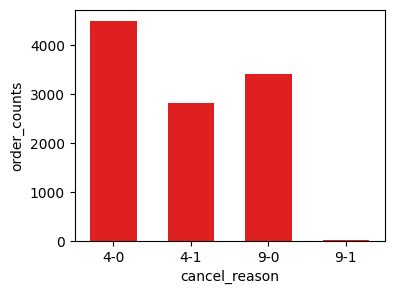

In [403]:
# plot the order_counts cancelled by the clients and system before and after the driver is assigned.
plt.figure(figsize=(4,3))
sns.barplot(data=num_cancelations, x='cancel_reason', y='order_counts', color='red', width=0.6)
plt.show()

### Failer to assign a driver seems to me the major reason for cancellation of the order.

## 2. Plot the distribution of failed orders by hours. Is there a trend that certain hours have an abnormally high proportion of one category or another? What hours are the biggest fails? How can this be explained?

In [406]:
orders.columns

Index(['order_datetime', 'origin_longitude', 'origin_latitude', 'm_order_eta',
       'order_gk', 'order_status_key', 'is_driver_assigned_key',
       'cancellations_time_in_seconds'],
      dtype='object')

In [407]:
# extract the hour from the order time by slicing the string and convert to intigets
orders['hours'] = orders['order_datetime'].str[:2].astype(int)
orders.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds,hours
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0,18
1,20:57:32,-0.950385,51.456843,0.0,3000583116437,4,0,128.0,20
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0,12
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0,13
4,21:24:45,-0.967605,51.458236,0.0,3000583140877,9,0,0.0,21


In [408]:
orders['cancel_reason'] = orders['order_status_key'].astype(str) + '-' + orders['is_driver_assigned_key'].astype(str)
orders.columns

Index(['order_datetime', 'origin_longitude', 'origin_latitude', 'm_order_eta',
       'order_gk', 'order_status_key', 'is_driver_assigned_key',
       'cancellations_time_in_seconds', 'hours', 'cancel_reason'],
      dtype='object')

In [409]:
# count the number of orders cancelled by client and system, driver assigned and time of cancellation.
cancellation_hour = orders.groupby(['cancel_reason','hours'])['order_gk'].count().reset_index(name='ordcounts')
cancellation_hour_pivoted = cancellation_hour.pivot(index='hours', columns='cancel_reason', values='ordcounts').reset_index()
cancellation_hour_pivoted

cancel_reason,hours,4-0,4-1,9-0,9-1
0,0,298.0,120.0,263.0,2.0
1,1,219.0,88.0,164.0,NaN
2,2,237.0,78.0,240.0,NaN
3,3,224.0,64.0,225.0,NaN
4,4,50.0,41.0,61.0,NaN
5,5,15.0,25.0,27.0,NaN
6,6,67.0,47.0,45.0,NaN
7,7,164.0,156.0,127.0,NaN
8,8,413.0,314.0,355.0,NaN
9,9,148.0,156.0,108.0,NaN


In [410]:
cancellation_hour_pivoted.columns.name = None
cancellation_hour_pivoted.columns

Index(['hours', '4-0', '4-1', '9-0', '9-1'], dtype='object')

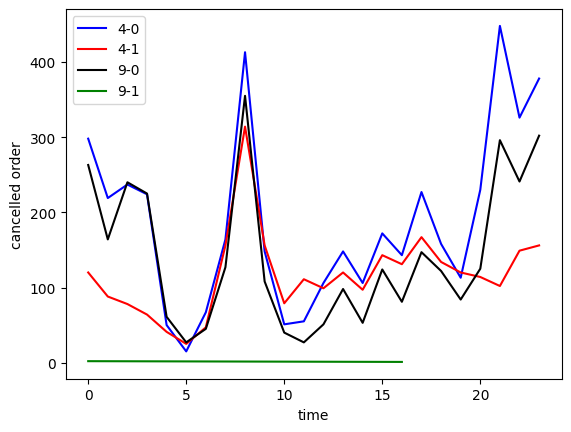

In [411]:
# plot with line chart the cancellation trend.
sns.lineplot(data=cancellation_hour_pivoted, x='hours',y='4-0', color='blue', label='4-0')
sns.lineplot(data=cancellation_hour_pivoted, x='hours',y='4-1', color='red', label='4-1')
sns.lineplot(data=cancellation_hour_pivoted, x='hours',y='9-0', color='black', label='9-0')
sns.lineplot(data=cancellation_hour_pivoted, x='hours',y='9-1', color='green', label='9-1')
plt.legend()
plt.ylabel('cancelled order')
plt.xlabel('time')
plt.show()

### cancellation of order at 8AM in the morning is generally higher irrespective of who initiated it or driver assigned or not. But still cancellation by clients due to failer to assign a driver stands out higher. The cacnellation rate is also very high in the times between 8 PM and 3AM in the morning.  

## 3. Plot the average time to cancellation with and without driver, by the hour. If there are any outliers in the data, it would be better to remove them. Can we draw any conclusions from this plot?

In [414]:
# call the dataframe.
orders.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds,hours,cancel_reason
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0,18,4-1
1,20:57:32,-0.950385,51.456843,0.0,3000583116437,4,0,128.0,20,4-0
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0,12,4-1
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0,13,4-1
4,21:24:45,-0.967605,51.458236,0.0,3000583140877,9,0,0.0,21,9-0


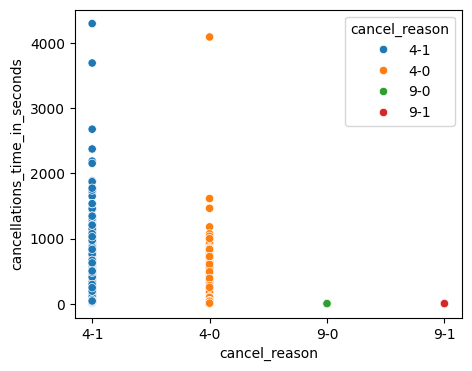

In [415]:
# Observe the distriution of the cancellation times.
plt.figure(figsize=(5,4))
sns.scatterplot(data=orders, x='cancel_reason', y='cancellations_time_in_seconds', hue='cancel_reason')
plt.show()

#### The above scatter plot shows that the cancellation by the system is authomatic and has not time delayance. Whereas client cancelled show some outliers which need to be removed. 

In [417]:
# from the order dataframe extract client cancelled orders.
clients = orders.query('order_status_key == 4')
clients.shape

(7307, 10)

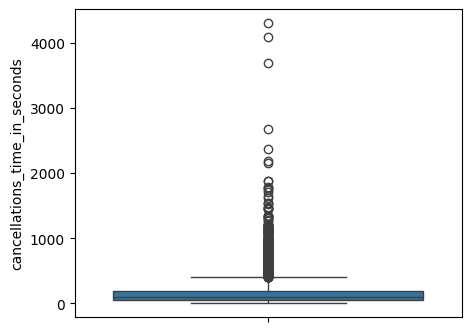

In [418]:
# plot a box plot to determine the out liers.
plt.figure(figsize=(5,4))
sns.boxplot(data=clients, y='cancellations_time_in_seconds')#, hue='cancel_reason')
plt.show()

In [419]:
# calculate Inter Quartile Range of the data.
Q3 = clients['cancellations_time_in_seconds'].quantile(0.75)
Q1 = clients['cancellations_time_in_seconds'].quantile(0.25)
IQR = Q3 - Q1
IQR

142.5

In [420]:
# determien the upper limit of the data ddtistribution.
upper_limit = Q3 + 3*IQR
upper_limit

615.0

In [421]:
# Filter out all rows containing cancellation time higher than the upper limit.
filt_data = clients.query('cancellations_time_in_seconds <= 615')
filt_data.head()

,order_datetime,origin_longitude,origin_latitude,m_order_eta,order_gk,order_status_key,is_driver_assigned_key,cancellations_time_in_seconds,hours,cancel_reason
0,18:08:07,-0.978916,51.456173,60.0,3000583041974,4,1,198.0,18,4-1
1,20:57:32,-0.950385,51.456843,0.0,3000583116437,4,0,128.0,20,4-0
2,12:07:50,-0.969520,51.455544,477.0,3000582891479,4,1,46.0,12,4-1
3,13:50:20,-1.054671,51.460544,658.0,3000582941169,4,1,62.0,13,4-1
9,06:33:52,-0.976216,51.433202,0.0,3000582765616,4,0,78.0,6,4-0


In [422]:
# calculate the average cancelation time based on driver assignemnt and time of cancellation.
avg_time = filt_data.groupby(['is_driver_assigned_key','hours'])['cancellations_time_in_seconds'].mean().reset_index(name='del_time').round(2)
avg_time_pivoted = avg_time.pivot(index='hours', columns='is_driver_assigned_key', values='del_time').reset_index()
avg_time_pivoted.columns = ['time','unassigned','assigned']
avg_time_pivoted

,time,unassigned,assigned
0,0,106.90,188.60
1,1,98.13,172.96
2,2,104.18,205.04
3,3,104.36,175.28
4,4,90.00,151.74
5,5,121.80,168.22
6,6,108.98,146.58
7,7,112.63,156.37
8,8,113.20,147.91
9,9,108.72,144.95


In [423]:
avg_time_pivoted.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   time        24 non-null     int64  
 1   unassigned  24 non-null     float64
 2   assigned    24 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 708.0 bytes


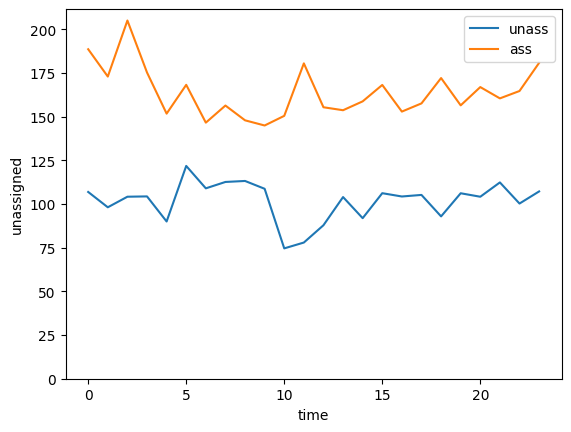

In [424]:
# Plot a line graph to observe the cancellation time.
sns.lineplot(data=avg_time_pivoted, x='time', y='unassigned', label='unass')
sns.lineplot(data=avg_time_pivoted, x='time', y='assigned', label='ass')
plt.legend()
plt.ylim(0,)
plt.show()

#### Generally the clients cancel the order in less than 2 minutes if the driver is not assigned. If Assigne they could wait upto four minutes. The average time slightly vary between hours.

## 4. Plot the distribution of average ETA by hours. How can this plot be explained?

In [459]:
# calculate the average ETA.
avg_eta = orders.groupby('hours')['m_order_eta'].mean().reset_index()
avg_eta

,hours,m_order_eta
0,0,63.939971
1,1,60.675159
2,2,54.953153
3,3,48.417154
4,4,80.828947
5,5,153.402985
6,6,126.264151
7,7,203.588367
8,8,184.833641
9,9,191.172330


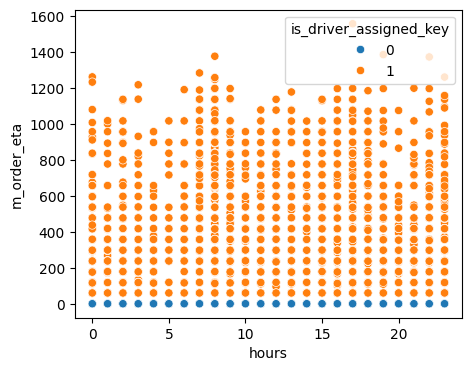

In [495]:
# plot the average ETA distibutions as scatter graph
plt.figure(figsize=(5,4))
sns.scatterplot(data=orders, x='hours', y='m_order_eta', hue='is_driver_assigned_key')
plt.show()

In [483]:
orders.columns

Index(['order_datetime', 'origin_longitude', 'origin_latitude', 'm_order_eta',
       'order_gk', 'order_status_key', 'is_driver_assigned_key',
       'cancellations_time_in_seconds', 'hours', 'cancel_reason'],
      dtype='object')

#### There is no considerable difference between times of the day for the the average ETA distribution. Where there is not driver assignment the ETA is 0 in all times of the day. 